# Transition tensors from the Reddit climate threads

Notation (as in Kozitsin): **s** own class of the replier, **l** influencer in the dyadic case (class of the parent),
**g** influencer in the group case (2m categories from the group's mean and variance), **k** output class.

This notebook only *calls* the three modules in the parent folder (`config.py`, `events.py`, `tensors.py`).
Every threshold lives in `config.py`; change it there, **restart the kernel**, and run again.

**Part A (this version): set up, load, and choose the cut-points from histograms, before looking at any transition.**

## 0. Setup

In [1]:
import sys
from pathlib import Path

# find the project folder (the one that holds config.py) by looking in the current folder, its parents,
# and an 'opinion_transitions' subfolder; works wherever the notebook is opened from
here = Path.cwd().resolve()
candidates = [here, *here.parents, here / "opinion_transitions"]
ROOT = next((p for p in candidates if (p / "config.py").exists() and (p / "events.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError(f"config.py and events.py not found from {here}; "
                            f"set ROOT = Path('/path/to/opinion_transitions') by hand")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

import config as cfg      # two UserWarnings about placeholder cuts are expected until Part A is finished
import events
import tensors

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)
print("config loaded from:", cfg.__file__)
print("raw data    :", cfg.DATA_RAW, "| exists:", cfg.DATA_RAW.exists())
print("cache       :", cfg.DATA_CACHE, "| exists:", cfg.DATA_CACHE.exists())

project root: /home/guial/projects/empirical-opinion-dynamics/reddit_climate
config loaded from: /home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py
raw data    : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/raw/filtered_subs_and_threads_anonymized | exists: True
cache       : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/cache | exists: True


/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:231: UserWarning: CUTS are placeholders: choose them from the score histogram before looking at transitions, then set CUTS_CHOSEN_FROM_HISTOGRAM = True.
  validate()
/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:231: UserWarning: VAR_CUT is a placeholder: choose it from the histogram of group variances before looking at transitions, then set VAR_CUT_CHOSEN_FROM_HISTOGRAM = True.
  validate()


## 1. Load the raw tables

`events.load_raw()` reads `data/cache/threads.parquet` and `submissions.parquet` if they exist, otherwise it reads
every CSV under `data/raw/` once and writes those two parquet files (score column converted to float, `NI` to NaN).
If you already have your own parquet files, put them in `data/cache/` with those names.

In [2]:
threads, submissions = events.load_raw()
print("comments   :", f"{len(threads):,}", "| paper Table 1: 363,350 (we expect about 78%)")
print("submissions:", f"{len(submissions):,}")
threads.head(3)

comments   : 282,497 | paper Table 1: 363,350 (we expect about 78%)
submissions: 6,251


,comm_id,sub_id,parent_id,subreddit_id,author_id,created_at,predicted_stance_scores,subreddit,thread_id
0,comm71631,t3_sub3423,t1_comm71632,r/4,author26899,2021-02-22 04:26:38,NaN,subreddit4,lowvyz
1,comm71633,t3_sub3423,t1_comm71634,r/4,author26899,2021-02-22 04:25:20,0.0,subreddit4,lowvyz
2,comm71635,t3_sub3423,t1_comm71636,r/4,author19952,2021-02-21 20:33:18,NaN,subreddit4,lowvyz


Per subreddit, compared with Table 1 of the paper. The mapping `r/0..r/5` to names is in `config.SUBREDDIT_NAMES`; the submission counts must match the ones in the paper for the names to be right.

In [3]:
paper = {"bayarea": (181, 7743), "California": (148, 7353), "collapse": (2429, 194695),
         "news": (385, 60509), "politics": (490, 43721), "AskReddit": (2618, 49329)}   # (submissions, comments)

by_sr = pd.DataFrame({"submissions": submissions.groupby(cfg.RAW_SUBREDDIT_ID).size(),
                      "comments": threads.groupby(cfg.RAW_SUBREDDIT_ID).size()})
by_sr["name_in_config"] = by_sr.index.map(cfg.SUBREDDIT_NAMES)
by_sr["paper_submissions"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[0])
by_sr["paper_comments"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[1])
by_sr["share_of_paper_comments"] = (by_sr["comments"] / by_sr["paper_comments"]).round(2)
by_sr["names_match"] = by_sr["submissions"] == by_sr["paper_submissions"]
by_sr

,submissions,comments,name_in_config,paper_submissions,paper_comments,share_of_paper_comments,names_match
subreddit_id,,,,,,,
r/0,181,6298,bayarea,181,7743,0.81,True
r/1,148,4910,California,148,7353,0.67,True
r/2,2429,175033,collapse,2429,194695,0.90,True
r/3,385,37568,news,385,60509,0.62,True
r/4,490,26845,politics,490,43721,0.61,True
r/5,2618,31843,AskReddit,2618,49329,0.65,True


## 2. Choose `CUTS` from the histogram of raw scores

The classes are `against` (x below the first cut), `neutral` (between the cuts) and `favour` (above the second cut).
Look at where the scores pile up before choosing. Do not look at transitions to tune this.

items: 288,748 | scored: 172,278 (59.7%) | NI: 116,470


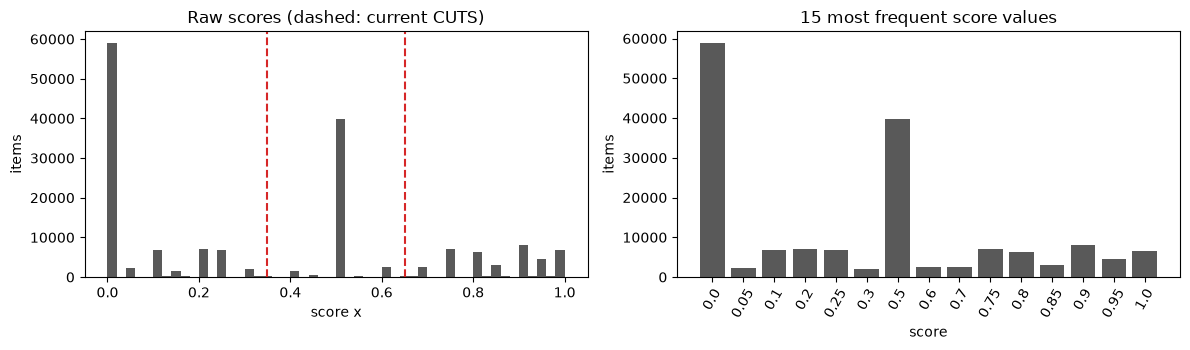

In [4]:
items = events.build_items(threads, submissions)
x = items["x"].dropna()
print(f"items: {len(items):,} | scored: {len(x):,} ({len(x) / len(items):.1%}) | NI: {items['x'].isna().sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(x, bins=50, color="0.35")
for c in cfg.CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Raw scores (dashed: current CUTS)", xlabel="score x", ylabel="items")
top = x.round(2).value_counts().head(15).sort_index()
ax[1].bar(top.index.astype(str), top.values, color="0.35")
ax[1].set(title="15 most frequent score values", xlabel="score", ylabel="items")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [5]:
cls = pd.Series(events.to_class(x, cfg.CUTS)).map(dict(enumerate(cfg.CLASS_LABELS)))
print("share of scored items per class with the current CUTS", cfg.CUTS)
print(cls.value_counts(normalize=True).reindex(cfg.CLASS_LABELS).round(3).to_string())
# how many items sit exactly on a cut or within 0.02 of it: these are the ones whose class is fragile
for c in cfg.CUTS:
    print(f"items within 0.02 of cut {c}: {((x - c).abs() <= 0.02).mean():.1%}")

share of scored items per class with the current CUTS (0.35, 0.65)
against    0.502
neutral    0.267
favour     0.231
items within 0.02 of cut 0.35: 0.3%
items within 0.02 of cut 0.65: 0.2%


## 3. Choose `VAR_CUT` from the histogram of group variances

For every reply we compute its group (the parent if scored and written by someone else, plus the earlier scored replies
to the same parent by other authors) and the mean and variance of the **raw** scores. These numbers do not depend on
`CUTS`, so this is safe to look at before choosing. This step builds the replies table, the own opinion `s`, and the
group statistics for the whole dataset; it can take a minute or two.

In [6]:
rep = events.build_replies(items)
rep = events.add_own_opinion(rep, items)
rep = events.add_group_stats(rep)
print(f"replies: {len(rep):,} | with a group of >= {cfg.MIN_MEMBERS} scored members: {(rep['g_n'] >= cfg.MIN_MEMBERS).sum():,}")
print("group size (scored members) for replies that have a group:")
print(rep.loc[rep["g_n"] >= 1, "g_n"].describe(percentiles=[.5, .9, .99]).round(1).to_string())

replies: 282,497 | with a group of >= 2 scored members: 67,563
group size (scored members) for replies that have a group:
count    135080.0
mean          8.0
std          20.5
min           1.0
50%           2.0
90%          19.0
99%         100.0
max         336.0


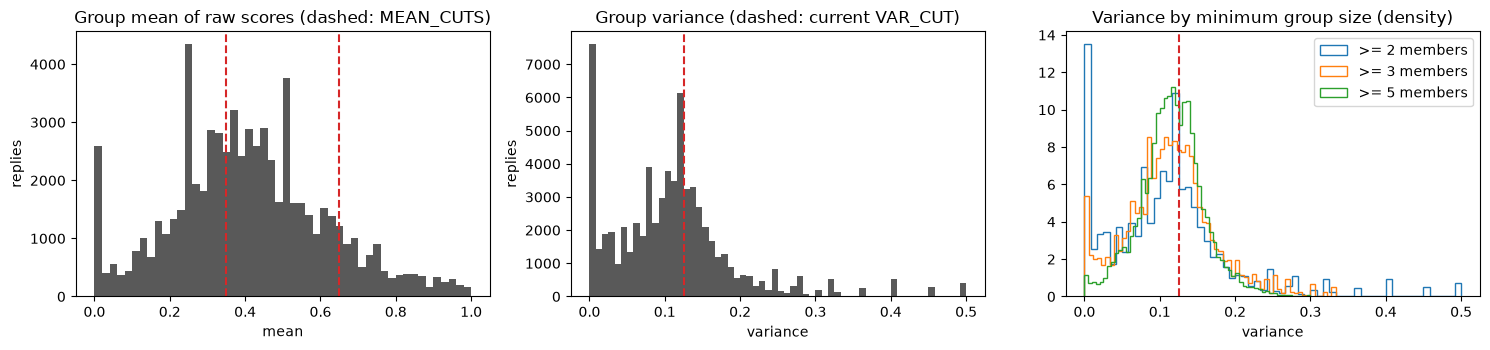

In [7]:
grp = rep[rep["g_n"] >= cfg.MIN_MEMBERS]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(grp["g_mu"], bins=50, color="0.35")
for c in cfg.MEAN_CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Group mean of raw scores (dashed: MEAN_CUTS)", xlabel="mean", ylabel="replies")
ax[1].hist(grp["g_var"], bins=60, color="0.35")
ax[1].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[1].set(title="Group variance (dashed: current VAR_CUT)", xlabel="variance", ylabel="replies")
for n_min, col in ((2, "C0"), (3, "C1"), (5, "C2")):
    ax[2].hist(rep.loc[rep["g_n"] >= n_min, "g_var"], bins=60, histtype="step", density=True, color=col, label=f">= {n_min} members")
ax[2].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[2].set(title="Variance by minimum group size (density)", xlabel="variance"); ax[2].legend()
plt.tight_layout(); plt.show()

In [8]:
# quantiles help to pick a cut: the bulk of 'consensus' groups should be clearly below it
kind = "unbiased sample variance" if cfg.VAR_UNBIASED else "population variance"
q = grp["g_var"].quantile([.1, .25, .5, .6, .7, .75, .8, .9]).round(4)
print(f"quantiles of the group {kind} (groups with >= MIN_MEMBERS members):")
print(q.to_string())
print("\nshare of groups called 'divided' for some candidate VAR_CUT values:")
cand = [0.02, 0.04, 0.06, 0.08, 0.10, 0.125, 0.15, 0.20, 0.25]
print(pd.Series({c: (grp["g_var"] >= c).mean() for c in cand}).round(3).to_string())
two = 2.0 if cfg.VAR_UNBIASED else 4.0     # 2 members: variance = (a - b)^2 / two
print(f"\nNote: with 2 members the variance is (a - b)^2 / {two:.0f}, so VAR_CUT = {cfg.VAR_CUT} means the two scores differ by > {(cfg.VAR_CUT * two) ** .5:.2f}.")

# the point of VAR_UNBIASED: the average variance should not depend on the group size
size = grp["g_n"].clip(upper=10).astype(int).rename("members (10 = 10 or more)")
by_size = pd.DataFrame({"groups": grp.groupby(size).size(),
                        "mean_var_pop": grp.groupby(size)["g_var_pop"].mean(),
                        "mean_var_used": grp.groupby(size)["g_var"].mean(),
                        "median_var_used": grp.groupby(size)["g_var"].median(),
                        "share_divided": grp.groupby(size)["g_var"].apply(lambda v: (v >= cfg.VAR_CUT).mean())}).round(4)
by_size

quantiles of the group unbiased sample variance (groups with >= MIN_MEMBERS members):
0.10    0.0050
0.25    0.0558
0.50    0.1074
0.60    0.1233
0.70    0.1340
0.75    0.1425
0.80    0.1532
0.90    0.2008

share of groups called 'divided' for some candidate VAR_CUT values:
0.020    0.860
0.040    0.800
0.060    0.741
0.080    0.665
0.100    0.550
0.125    0.390
0.150    0.215
0.200    0.102
0.250    0.058

Note: with 2 members the variance is (a - b)^2 / 2, so VAR_CUT = 0.125 means the two scores differ by > 0.50.


,groups,mean_var_pop,mean_var_used,median_var_used,share_divided
members (10 = 10 or more),,,,,
2,17807,0.0511,0.1022,0.0450,0.3585
3,8590,0.0725,0.1087,0.0833,0.3658
4,5383,0.0841,0.1121,0.1006,0.4221
5,3859,0.0916,0.1146,0.1145,0.4491
6,2970,0.0964,0.1157,0.1177,0.4559
7,2380,0.0989,0.1154,0.1154,0.4227
8,1970,0.1011,0.1156,0.1150,0.4279
9,1683,0.1024,0.1151,0.1157,0.4248
10,22921,0.1107,0.1162,0.1164,0.3882


## 4. Check that the 6 categories fill with the candidate cuts

This only counts how many groups land in each (own class × group category) cell, which is allowed before looking at
transitions. Change `CUTS`, `MEAN_CUTS` and `VAR_CUT` in `config.py` (and restart the kernel) if rows are nearly empty.

In [9]:
def category_fill(min_members):
    d = rep[(rep["g_n"] >= min_members) & rep[cfg.COL_S].notna()]
    mean_level = events.to_class(d["g_mu"], cfg.MEAN_CUTS)
    g = (2 * mean_level + (d["g_var"] >= cfg.VAR_CUT)).astype(int)
    tab = pd.crosstab(d[cfg.COL_S].astype(int), g).reindex(index=range(cfg.N_CLASSES), columns=range(cfg.N_G), fill_value=0)
    tab.index = [f"s={l}" for l in cfg.CLASS_LABELS]
    tab.columns = list(cfg.G_LABELS)
    return tab

for m in (2, 3):
    print(f"group events per (s, g) cell with >= {m} members (before date / gap filters):")
    display(category_fill(m))

group events per (s, g) cell with >= 2 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,6058,2119,4864,5864,2127,391
s=neutral,2919,1010,2582,2961,1141,198
s=favour,2668,978,2346,2710,1117,217


group events per (s, g) cell with >= 3 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,4571,1404,3841,4679,1076,269
s=neutral,2153,669,2016,2336,574,131
s=favour,1945,641,1852,2162,540,131


### Decision to record (end of Part A)

1. Write the chosen `CUTS` and `VAR_CUT` (and `MEAN_CUTS` if you change it) in `config.py`.
2. Set `CUTS_CHOSEN_FROM_HISTOGRAM = True` and `VAR_CUT_CHOSEN_FROM_HISTOGRAM = True` there, so the warnings disappear.
3. **Restart the kernel** so the new values are read, then continue with Part B (events and funnels).

Rule: cuts are fixed here and never revisited after seeing the tensors.

## B1. Composition representation: how many events per cell?

`events.build_events()` now returns a third table, `comp`, with the composition cell **c** and the mean x variance category **g**
on the same replies. Choose the number of classes in `config.py` (`N_CLASSES`) or here with `cfg.set_classes(m)`;
`COMP_MODE`, `COMP_MAX_SIZE`, `COMP_GRID` and `COMP_SIZE_EDGES` define the cells.
A row of the tensor is a pair (s, influencer); what matters is how many events each row holds, not the number of cells.

In [10]:
cfg.set_classes(3)                      # try 2 as well
res = events.build_events(threads, submissions, verbose=False)
res["funnel_comp"]

,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,group has >= 2 scored members,42268,0.384,0.150
7,group has at most 5 members -> composition e...,22128,0.524,0.078


### Fill of the three summaries side by side
`rows_below_t` = share of (s, influencer) rows with fewer than t events; `events_in_rows_below_t` = share of events that sit in such rows; `prior_weight` = share of the estimate that comes from the shrinkage prior; `cmi_bias_bits` = plug-in bias of the information measure.

In [11]:
events.compare_fill(res).T

summary,l parent class,g mean x variance,h mean x opposed pairs,g (comp events),h (comp events),c composition
influencer,l,g,h,g,h,c
categories,3,6,6,6,6,52
rows,9,18,18,18,18,156
rows_nonempty,9,18,18,18,18,154
events,87032,42268,42268,22128,22128,22128
median_R,8045.0,2236.0,2119.5,1176.5,1012.0,64.5
min_R_nonempty,5550,198,179,155,112,1
cells_sk_zero,0.0,0.0,0.0,0.0,0.0,0.025641
rows_below_10,0.0,0.0,0.0,0.0,0.0,0.076923
events_in_rows_below_10,0.0,0.0,0.0,0.0,0.0,0.00226


### Composition cells by group size

In [12]:
display(events.fill_by_size(res["comp"]).round(3))

,bin,sizes,cells,cells_observed,events,events_per_cell,rows_below_min,share_of_events
0,0,2,6,6,11279,626.611,0.111,0.510
1,1,3,10,10,5149,171.633,0.867,0.233
2,2,4,15,15,3330,74.000,1.000,0.150
3,3,5,21,21,2370,37.619,1.000,0.107


### The thinnest and the fullest rows (s, c)

,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
88,1,36,neutral,n=5: 0-5-0,0,0,0,0,True
140,2,36,favour,n=5: 0-5-0,0,0,0,0,True
36,0,36,against,n=5: 0-5-0,1,1,0,0,True
72,1,20,neutral,n=4: 0-4-0,3,2,1,0,True
139,2,35,favour,n=5: 0-4-1,3,1,2,0,True
87,1,35,neutral,n=5: 0-4-1,3,1,1,1,True
124,2,20,favour,n=4: 0-4-0,4,3,0,1,True
35,0,35,against,n=5: 0-4-1,6,2,0,4,True
135,2,31,favour,n=5: 0-0-5,6,2,1,3,True
145,2,41,favour,n=5: 1-4-0,8,4,2,2,True


,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
109,2,5,favour,n=2: 2-0-0,591,321,123,147,False
108,2,4,favour,n=2: 1-1-0,601,296,165,140,False
56,1,4,neutral,n=2: 1-1-0,622,299,181,142,False
55,1,3,neutral,n=2: 1-0-1,633,278,175,180,False
57,1,5,neutral,n=2: 2-0-0,639,352,169,118,False
0,0,0,against,n=2: 0-0-2,696,298,157,241,False
1,0,1,against,n=2: 0-1-1,796,358,218,220,False
3,0,3,against,n=2: 1-0-1,1199,627,287,285,False
4,0,4,against,n=2: 1-1-0,1206,632,335,239,False
5,0,5,against,n=2: 2-0-0,1263,748,311,204,False


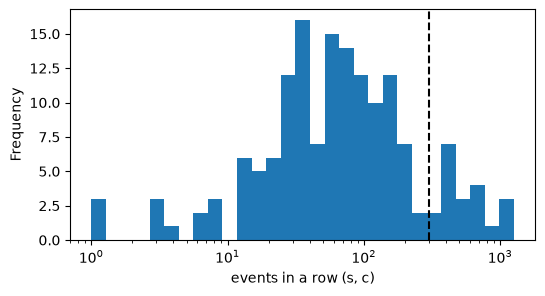

In [13]:
t = events.fill_table(res["comp"], cfg.COL_C)
display(t.sort_values("R").head(10)); display(t.sort_values("R").tail(10))
ax = t["R"].clip(lower=1).plot.hist(bins=np.logspace(0, np.log10(t["R"].max() + 1), 30), logx=True, figsize=(6, 3))
ax.axvline(cfg.MIN_ROW_EVENTS, color="k", ls="--"); ax.set_xlabel("events in a row (s, c)"); plt.show()

### Scan: which m and which cell definition keep the rows filled?

In [14]:
scan = events.scan_compositions(threads, submissions, ms=(2, 3), max_sizes=(3, 4, 5, 6), grids=(3, 4, 6))
scan.round(3)

,m,mode,option,categories,rows,events,median_R,min_R_nonempty,rows_below_300,events_in_rows_below_300,prior_weight,cmi_bias_bits
0,2,counts,n<=3,7,14,16428,936.5,283,0.143,0.035,0.040,0.001
1,2,counts,n<=4,12,24,19758,555.0,104,0.250,0.065,0.055,0.001
2,2,counts,n<=5,18,36,22128,323.5,50,0.417,0.121,0.069,0.001
3,2,counts,n<=6,25,50,23971,261.5,17,0.580,0.189,0.083,0.001
4,2,shares,grid 1/3,4,8,42268,5181.0,1917,0.000,0.000,0.009,0.000
5,2,shares,grid 1/4,5,10,42268,3387.5,1788,0.000,0.000,0.012,0.000
6,2,shares,grid 1/6,7,14,42268,3114.5,778,0.000,0.000,0.016,0.000
7,3,counts,n<=3,16,48,16428,214.5,30,0.583,0.249,0.116,0.004
8,3,counts,n<=4,31,93,19758,115.0,3,0.785,0.376,0.157,0.007
9,3,counts,n<=5,52,156,22128,64.5,1,0.872,0.443,0.194,0.010


## B2. Which measure of the group captures its influence: unbiased variance or opposed pairs?

Every group has a **lean** (its mean level) and a **spread**. Two candidates for the spread coordinate, both unbiased in the group size:

* **variance**: the unbiased sample variance of the raw scores (`g = 2 * lean + variance level`);
* **opposed pairs**: `O` = share of pairs of members with one in the first and one in the last class, computed from the composition (`h = 2 * lean + opposition level`). `M` = share of mildly disagreeing pairs.

`OPP_CUT = None` in `config.py` chooses the cut of `O` that labels the same share of events 'high' as `VAR_CUT`, so the two summaries split the events in the same proportion. Both summaries have the same number of categories and are scored on the same events.

In [15]:
cfg.set_classes(3)      # polarization needs at least 3 classes: with 2 every disagreement counts as 'opposed'
res = events.build_events(threads, submissions, verbose=True)
grp_ev = res["group"]

OPP_CUT used: 0.263 (matched to VAR_CUT) | share of group events with high variance 0.389, with high opposition 0.389

=== funnel_dyadic ===
                                              step      n  share_of_previous  share_of_comments
                                          comments 282497                NaN              1.000
                          reply is scored (not NI) 167274              0.592              0.592
                                      author known 167274              1.000              0.592
                        parent present in the data 156532              0.936              0.554
             reply within 2020-07-01 .. 2022-12-31 156517              1.000              0.554
replier has an earlier scored item (own opinion s) 110131              0.704              0.390
                                  parent is scored  87887              0.798              0.311
               not a self-reply  ->  dyadic events  87032              0.990              0

### The two spread coordinates: distributions and their relation to group size

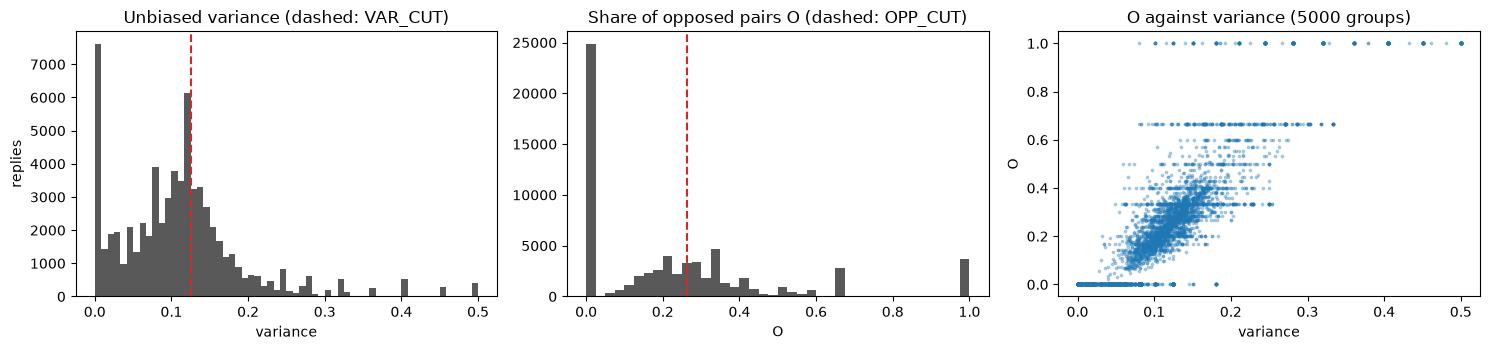

rank correlation variance vs O: 0.852


,groups,mean_O,mean_M,mean_var,share_high_var,share_high_O
members (10 = 10 or more),,,,,,
2,17807,0.209,0.363,0.102,0.359,0.209
3,8590,0.227,0.356,0.109,0.366,0.420
4,5383,0.236,0.355,0.112,0.422,0.495
5,3859,0.242,0.349,0.115,0.449,0.502
6,2970,0.243,0.353,0.116,0.456,0.538
7,2380,0.243,0.354,0.115,0.423,0.462
8,1970,0.244,0.354,0.116,0.428,0.449
9,1683,0.241,0.354,0.115,0.425,0.439
10,22921,0.242,0.354,0.116,0.388,0.421


In [16]:
rep_ = res["replies"]
elig = rep_[rep_["g_n"] >= cfg.MIN_MEMBERS]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(elig["g_var"], bins=60, color="0.35"); ax[0].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[0].set(title="Unbiased variance (dashed: VAR_CUT)", xlabel="variance", ylabel="replies")
ax[1].hist(elig["g_opp"].dropna(), bins=40, color="0.35"); ax[1].axvline(res["opp_cut"], color="C3", ls="--")
ax[1].set(title="Share of opposed pairs O (dashed: OPP_CUT)", xlabel="O")
ax[2].scatter(elig["g_var"].sample(min(len(elig), 5000), random_state=0), elig.loc[:, "g_opp"].sample(min(len(elig), 5000), random_state=0), s=3, alpha=.3)
ax[2].set(title="O against variance (5000 groups)", xlabel="variance", ylabel="O")
plt.tight_layout(); plt.show()
print("rank correlation variance vs O:", round(elig[["g_var", "g_opp"]].corr(method="spearman").iloc[0, 1], 3))

size = elig["g_n"].clip(upper=10).astype(int).rename("members (10 = 10 or more)")
display(pd.DataFrame({"groups": elig.groupby(size).size(),
                      "mean_O": elig.groupby(size)["g_opp"].mean(),
                      "mean_M": elig.groupby(size)["g_mild"].mean(),
                      "mean_var": elig.groupby(size)["g_var"].mean(),
                      "share_high_var": elig.groupby(size)["g_var"].apply(lambda v: (v >= cfg.VAR_CUT).mean()),
                      "share_high_O": elig.groupby(size)["g_opp"].apply(lambda v: (v >= res["opp_cut"]).mean())}).round(3))

Both columns `mean_O` and `mean_var` should be roughly flat in the group size if the unbiased versions work. How often the two summaries label a group the same way:

In [17]:
print("agreement of the 'high' labels (variance vs opposed pairs):")
display(pd.crosstab(grp_ev["var"] >= cfg.VAR_CUT, grp_ev["opp"] >= res["opp_cut"], normalize=True,
                    rownames=["high variance"], colnames=["high opposition"]).round(3))
display(events.compare_fill(res).T)

agreement of the 'high' labels (variance vs opposed pairs):


high opposition,False,True
high variance,,
False,0.534,0.077
True,0.077,0.312


summary,l parent class,g mean x variance,h mean x opposed pairs,g (comp events),h (comp events),c composition
influencer,l,g,h,g,h,c
categories,3,6,6,6,6,52
rows,9,18,18,18,18,156
rows_nonempty,9,18,18,18,18,154
events,87032,42268,42268,22128,22128,22128
median_R,8045.0,2236.0,2119.5,1176.5,1012.0,64.5
min_R_nonempty,5550,198,179,155,112,1
cells_sk_zero,0.0,0.0,0.0,0.0,0.0,0.025641
rows_below_10,0.0,0.0,0.0,0.0,0.0,0.076923
events_in_rows_below_10,0.0,0.0,0.0,0.0,0.0,0.00226


### The test: held-out log-loss of every summary on the same events

Bits per event, lower is better. `none` knows only the replier's own class. `size` is a **control**: the information carried by group size alone. `lean` is the mean level alone. `g` is lean + variance, `h` is lean + opposed pairs, `gh` uses both. `better_than_ref` is the gain over `g` in bits per event, with a user-bootstrap interval: **positive and an interval above 0 means that summary predicts better than the variance**.

In [ ]:
cmp_group = tensors.compare_summaries(grp_ev)
print(f"{cmp_group['n_events']:,} events, {cmp_group['n_users']:,} users | reference summary: {cmp_group['ref']}")
cmp_group["table"].round(4)

### Does one coordinate add information beyond the other?

Permutation test of I(K; coordinate | strata): the coordinate is shuffled among events that share the same strata. `cmi_excess` is what the coordinate adds beyond those strata, in bits per event. The size class is always among the strata, so a coordinate that is just a proxy for group size adds nothing here.

The last two rows ask the question about **mild pairs**: does `M` add anything once the opposed pairs are known, and the other way round?

In [ ]:
cmp_group["added"].round(4)

### Are the mild pairs worth counting? The family D(w) = O + w·M

`w` is the weight of a mildly disagreeing pair relative to an opposed pair: **0** = opposed pairs only, **0.25** = variance of the class positions, **0.5** = mean absolute distance, **1** = every disagreeing pair counts the same. Each D(w) becomes a summary `lean level x high/low level` with the cut matched to the same share of 'high' events as `VAR_CUT`.

* `better_than_w0 > 0`: counting the mild pairs lowers the held-out loss.
* `better_than_ref` compares with `g` (variance of the **raw** scores): D(0.25) against `g` shows what the position of the scores inside each class adds.

In [ ]:
cmp_group["family"].round(4)

Repeat on the composition events (groups of at most `COMP_MAX_SIZE` members), which also contain the composition cell `c`:

In [ ]:
cmp_comp = tensors.compare_summaries(res["comp"])
print(f"{cmp_comp['n_events']:,} events")
display(cmp_comp["table"].round(4)); display(cmp_comp["added"].round(4))

### Robustness (change in `config.py`, restart the kernel, rerun B2)

* `MIN_MEMBERS = 3`: for 2 members `O` is only 0 or 1.
* `OPP_CUT` as a fixed number instead of the matched one.
* `CUTS` of the individual classes (the opposed pairs depend on them).
* Another `VAR_CUT` (the opposition cut follows it).